In [65]:
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings('ignore')

In [61]:
!pip install xgboost

In [23]:
df = pd.read_csv("DigitalSkySurvey.csv")

In [24]:
df.head()

,objid,ra,dec,u,g,r,i,z,run,rerun,camcol,field,specobjid,class,redshift,plate,mjd,fiberid
0,1.237650e+18,183.531326,0.089693,19.47406,17.04240,15.94699,15.50342,15.22531,752,301,4,267,3.722360e+18,STAR,-0.000009,3306,54922,491
1,1.237650e+18,183.598370,0.135285,18.66280,17.21449,16.67637,16.48922,16.39150,752,301,4,267,3.638140e+17,STAR,-0.000055,323,51615,541
2,1.237650e+18,183.680207,0.126185,19.38298,18.19169,17.47428,17.08732,16.80125,752,301,4,268,3.232740e+17,GALAXY,0.123111,287,52023,513
3,1.237650e+18,183.870529,0.049911,17.76536,16.60272,16.16116,15.98233,15.90438,752,301,4,269,3.722370e+18,STAR,-0.000111,3306,54922,510
4,1.237650e+18,183.883288,0.102557,17.55025,16.26342,16.43869,16.55492,16.61326,752,301,4,269,3.722370e+18,STAR,0.000590,3306,54922,512


In [25]:
columns_to_drop = ["objid", "specobjid", "rerun", "camcol", "field", "run"]

In [26]:
df.drop(columns_to_drop, axis=1, inplace=True)
df.head()

,ra,dec,u,g,r,i,z,class,redshift,plate,mjd,fiberid
0,183.531326,0.089693,19.47406,17.04240,15.94699,15.50342,15.22531,STAR,-0.000009,3306,54922,491
1,183.598370,0.135285,18.66280,17.21449,16.67637,16.48922,16.39150,STAR,-0.000055,323,51615,541
2,183.680207,0.126185,19.38298,18.19169,17.47428,17.08732,16.80125,GALAXY,0.123111,287,52023,513
3,183.870529,0.049911,17.76536,16.60272,16.16116,15.98233,15.90438,STAR,-0.000111,3306,54922,510
4,183.883288,0.102557,17.55025,16.26342,16.43869,16.55492,16.61326,STAR,0.000590,3306,54922,512


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ra        10000 non-null  float64
 1   dec       10000 non-null  float64
 2   u         10000 non-null  float64
 3   g         10000 non-null  float64
 4   r         10000 non-null  float64
 5   i         10000 non-null  float64
 6   z         10000 non-null  float64
 7   class     10000 non-null  object 
 8   redshift  10000 non-null  float64
 9   plate     10000 non-null  int64  
 10  mjd       10000 non-null  int64  
 11  fiberid   10000 non-null  int64  
dtypes: float64(8), int64(3), object(1)
memory usage: 937.6+ KB


In [28]:
df["class"].value_counts()

class
GALAXY    4998
STAR      4152
QSO        850
Name: count, dtype: int64

In [32]:
df.describe()

,ra,dec,u,g,r,i,z,redshift,plate,mjd,fiberid
count,9995.000000,9995.000000,9995.000000,9995.000000,9995.000000,9995.000000,9995.000000,9995.000000,9995.000000,9995.000000,9995.000000
mean,175.523276,14.831798,18.619770,17.371905,16.840648,16.583080,16.422153,0.141777,1459.287944,52942.115258,353.045223
std,47.790167,25.209343,0.828396,0.945577,1.067797,1.141700,1.202937,0.378598,1787.228251,1510.106872,206.323379
min,8.235100,-5.382632,12.988970,12.799550,12.431600,11.947210,11.610410,-0.004136,266.000000,51578.000000,1.000000
25%,157.368397,-0.539637,18.178150,16.815060,16.173140,15.853370,15.618035,0.000081,301.000000,51900.000000,186.000000
50%,180.393638,0.403084,18.853220,17.495120,16.858530,16.554390,16.388500,0.042522,441.000000,51997.000000,351.000000
75%,201.548093,35.596455,19.259280,18.010220,17.512165,17.257145,17.140930,0.092441,2559.000000,54468.000000,510.000000
max,260.884382,68.542265,19.599900,19.918970,24.802040,28.179630,22.833060,2.934467,8410.000000,57481.000000,1000.000000


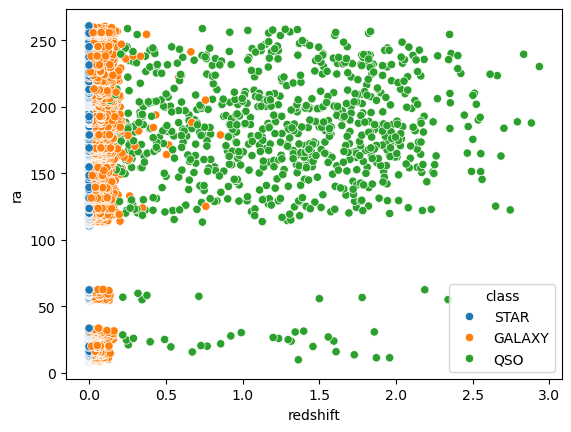

In [33]:
df = df[df["redshift"] < 3]

sns.scatterplot(data=df, x="redshift", y="ra", hue="class")
plt.show()

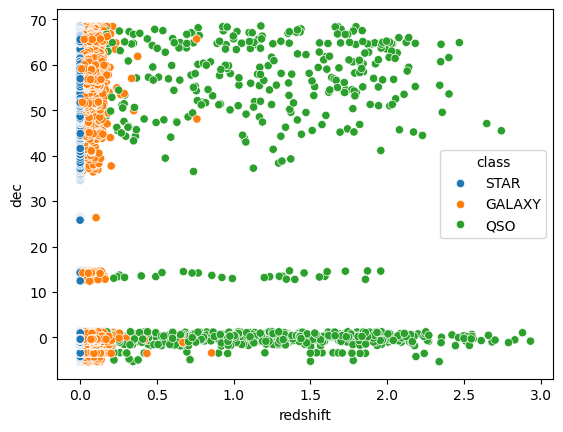

In [36]:
sns.scatterplot(data=df, x="redshift", y="dec", hue="class")
plt.show()

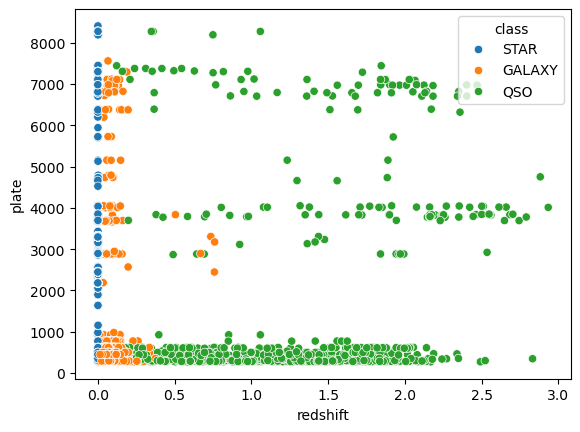

In [37]:
sns.scatterplot(data=df, x="redshift", y="plate", hue="class")
plt.show()

In [39]:
le = LabelEncoder()

df["class"] = le.fit_transform(df["class"])

In [40]:
df.corr()

,ra,dec,u,g,r,i,z,class,redshift,plate,mjd,fiberid
ra,1.000000,0.003373,0.031168,0.043716,0.046864,0.045469,0.042660,-0.043236,0.029909,-0.095845,-0.087281,0.057647
dec,0.003373,1.000000,0.035449,0.061662,0.063035,0.057845,0.056392,-0.058955,0.067323,0.087621,0.065658,0.155183
u,0.031168,0.035449,1.000000,0.849580,0.693113,0.603575,0.552568,-0.269151,0.174143,-0.128645,-0.168007,0.011698
g,0.043716,0.061662,0.849580,1.000000,0.958192,0.907600,0.879892,-0.099227,0.418527,-0.055278,-0.092984,0.047421
r,0.046864,0.063035,0.693113,0.958192,1.000000,0.977684,0.969252,0.049612,0.449999,0.018991,-0.010033,0.061232
i,0.045469,0.057845,0.603575,0.907600,0.977684,1.000000,0.981508,0.146802,0.438608,0.071936,0.049990,0.070093
z,0.042660,0.056392,0.552568,0.879892,0.969252,0.981508,1.000000,0.215808,0.429748,0.111212,0.094587,0.068066
class,-0.043236,-0.058955,-0.269151,-0.099227,0.049612,0.146802,0.215808,1.000000,-0.078016,0.586066,0.649297,0.053589
redshift,0.029909,0.067323,0.174143,0.418527,0.449999,0.438608,0.429748,-0.078016,1.000000,-0.048938,-0.069366,0.046530
plate,-0.095845,0.087621,-0.128645,-0.055278,0.018991,0.071936,0.111212,0.586066,-0.048938,1.000000,0.966870,0.229976


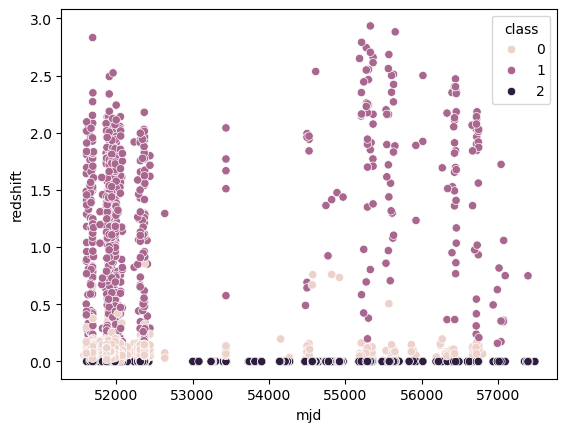

In [41]:
sns.scatterplot(data=df, x="mjd", y="redshift", hue="class")
plt.show()

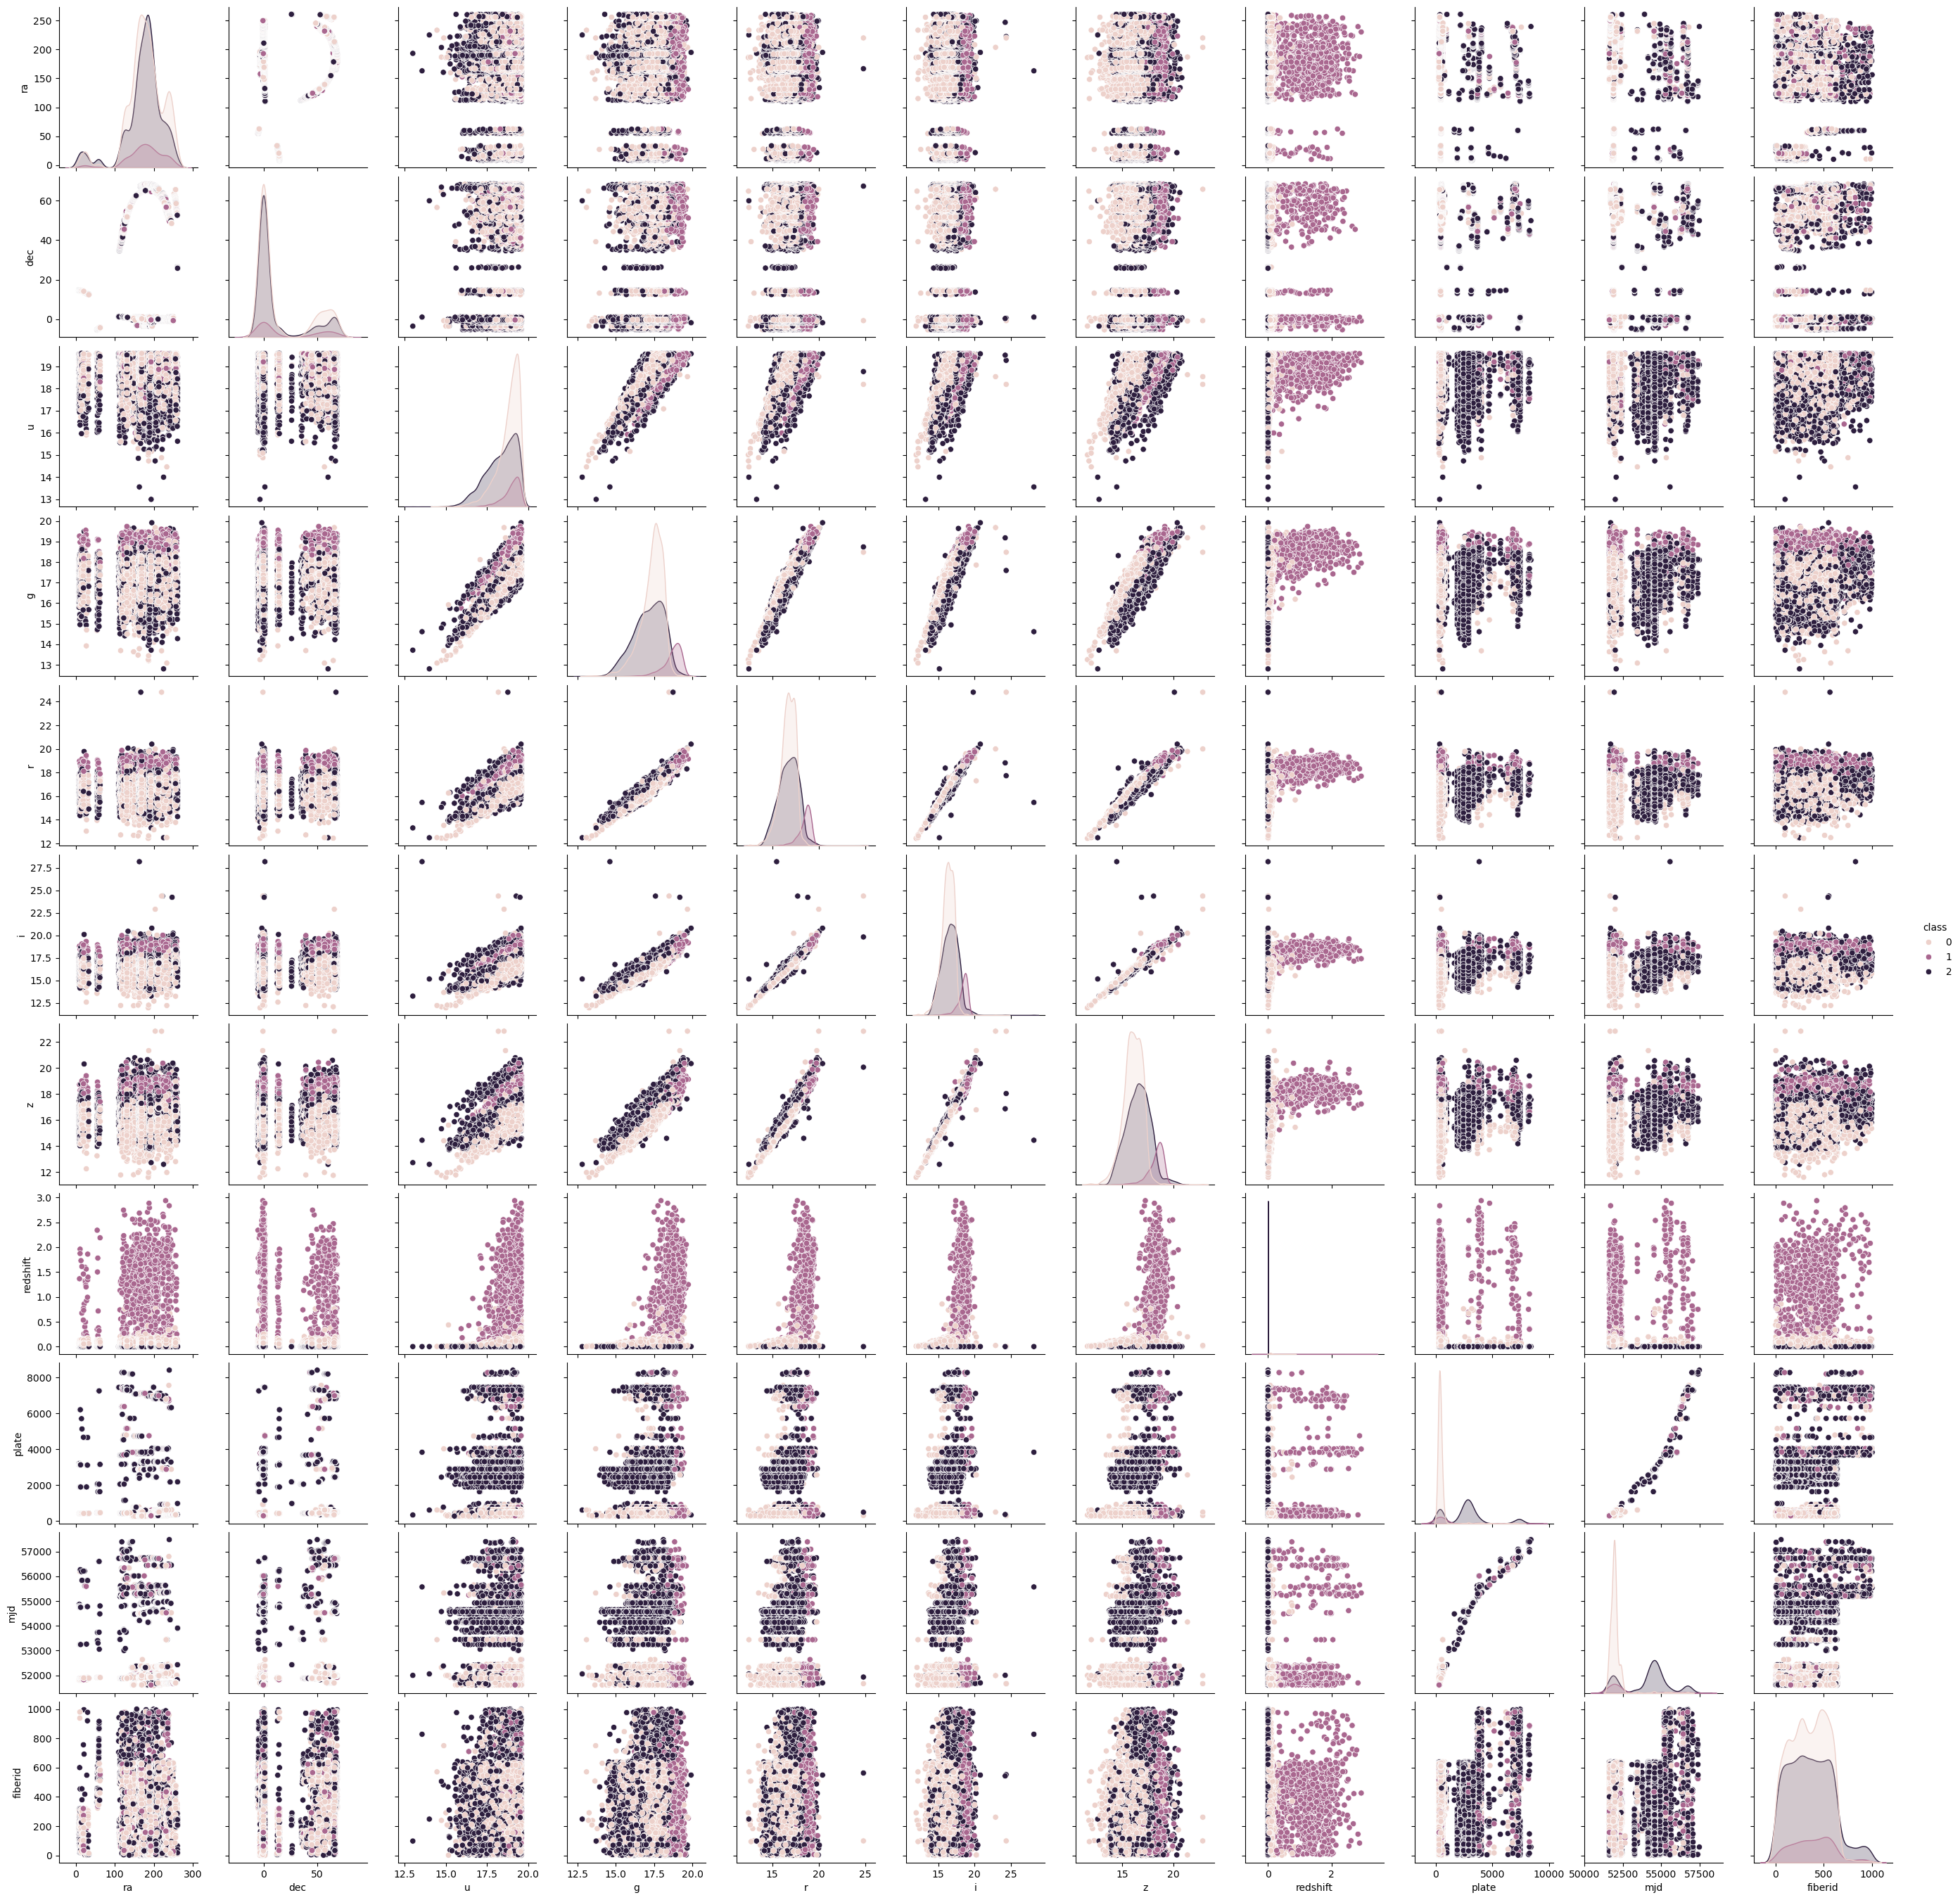

In [42]:
sns.pairplot(df, hue="class")
plt.show()

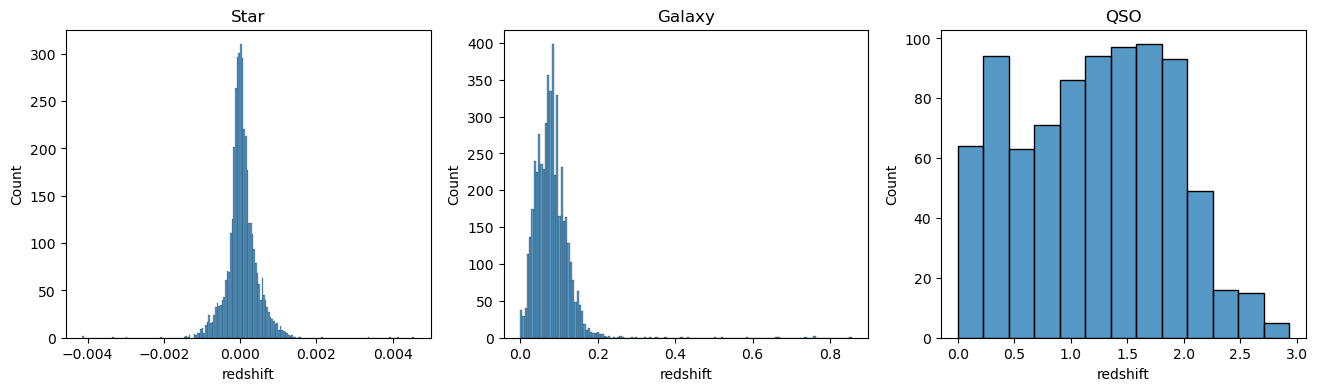

In [54]:
fig, axis = plt.subplots(nrows=1, ncols=3, figsize=(16,4))
ax = sns.histplot(df[df["class"] == 2].redshift, ax=axis[0])
ax.set_title("Star")
ax = sns.histplot(df[df["class"] == 0].redshift, ax=axis[1])
ax.set_title("Galaxy")
ax = sns.histplot(df[df["class"] == 1].redshift, ax=axis[2])
ax.set_title("QSO")
plt.show()

In [56]:
X = df.drop("class", axis=1)
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=15)

In [69]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", XGBClassifier(n_estimators=100))
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Accuracy Score:  0.9883953581432573
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

           0       0.98      0.99      0.99      1256
           1       0.97      0.91      0.94       232
           2       1.00      1.00      1.00      1011

    accuracy                           0.99      2499
   macro avg       0.98      0.97      0.98      2499
weighted avg       0.99      0.99      0.99      2499

------------------------------------------------------------
Confusion Matrix: 
 [[1247    6    3]
 [  20  212    0]
 [   0    0 1011]]


In [71]:
params = {
    "model__n_estimators" : [100, 200, 300, 500],
    "model__max_depth" : [5, 8, 12, 20, 30],
    "model__learning_rate" : [0.01, 0.1],
    "model__colsample_bytree" : [0.3, 0.4, 0.5, 0.8, 1]
}

grid = GridSearchCV(
    pipe,
    param_grid=params,
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)
y_pred1 = grid.predict(X_test)

Accuracy Score:  0.9883953581432573
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

           0       0.98      0.99      0.99      1256
           1       0.97      0.91      0.94       232
           2       1.00      1.00      1.00      1011

    accuracy                           0.99      2499
   macro avg       0.98      0.97      0.98      2499
weighted avg       0.99      0.99      0.99      2499

------------------------------------------------------------
Confusion Matrix: 
 [[1247    6    3]
 [  20  212    0]
 [   0    0 1011]]


In [72]:
print("Best Parameters: ", grid.best_params_)
print("-"*60)
print("Best Score: ", grid.best_score_)
print("-"*60)
print("Accuracy Score: ", accuracy_score(y_test, y_pred))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Best Parameters:  {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200}
------------------------------------------------------------
Best Score:  0.9910617745163443
------------------------------------------------------------
Accuracy Score:  0.9883953581432573
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

           0       0.98      0.99      0.99      1256
           1       0.97      0.91      0.94       232
           2       1.00      1.00      1.00      1011

    accuracy                           0.99      2499
   macro avg       0.98      0.97      0.98      2499
weighted avg       0.99      0.99      0.99      2499

------------------------------------------------------------
Confusion Matrix: 
 [[1247    6    3]
 [  20  212    0]
 [   0    0 1011]]
